# Databricks pipeline: Feature Engineering + MLflow + CodeCarbon (PySpark)
Predict a CrossFit athlete's deadlift with a random forest (Spark ML).
We build 2 versions of the features and train with 2 sets of hyperparameters, so 4 experiments in total.
Everything is done with Spark DataFrames, no pandas.

Before running: upload `athletes.csv` to the volume path used in section 1.

## Important: this notebook only runs on Databricks
It uses things that exist only inside a Databricks workspace, so it will not run on a laptop:
- `spark`, `dbutils` and `display()` are provided by the Databricks notebook environment.
- `FeatureEngineeringClient` (from `databricks.feature_engineering`) is the **Databricks feature store**. It saves the features as Unity Catalog tables and looks them up when we train. The local notebook uses Feast for the same job.
- The data is read from a Unity Catalog volume (`/Volumes/...`).

To run it, import this notebook into your Databricks workspace and attach compute (see the README).

In [0]:
%pip install codecarbon==2.7.1 databricks-feature-engineering

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
dbutils.library.restartPython()

In [0]:
import matplotlib.pyplot as plt
import mlflow
from codecarbon import OfflineEmissionsTracker
from databricks.feature_engineering import FeatureEngineeringClient, FeatureLookup
from mlflow.tracking import MlflowClient
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import RandomForestRegressor
from pyspark.sql import functions as F

catalog = 'workspace'
schema = 'default'
fe = FeatureEngineeringClient()

/local_disk0/.ephemeral_nfs/envs/pythonEnv-4b6b2870-585f-4725-8ed8-18915453655c/lib/python3.12/site-packages/codecarbon/emissions_tracker.py:18: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  from codecarbon.core import cpu, gpu, powermetrics


## 1. Load and clean the data

In [0]:
df = spark.read.csv('/Volumes/workspace/default/raw/athletes.csv', header=True, inferSchema=True)

# keep only the columns we need and drop rows with missing values
cols = ['athlete_id', 'gender', 'age', 'height', 'weight', 'candj', 'snatch', 'backsq', 'deadlift']
df = df.select(cols).dropna().dropDuplicates(['athlete_id'])
df = df.filter(F.col('gender').isin('Male', 'Female'))

# remove unrealistic values
df = df.filter(F.col('age').between(14, 80) & F.col('height').between(48, 84) & F.col('weight').between(90, 400))
df = df.filter(F.col('candj').between(40, 600) & F.col('snatch').between(30, 500))
df = df.filter(F.col('backsq').between(50, 800) & F.col('deadlift').between(80, 900))
df = df.withColumn('athlete_id', F.col('athlete_id').cast('long'))

print(df.count(), 'athletes after cleaning')

70227 athletes after cleaning


## 2. Create two versions of the features
- **v1:** body measurements only
- **v2:** v1 plus the other lifts and each lift divided by bodyweight

In [0]:
v1 = df.select(
    'athlete_id', 'age', 'height', 'weight',
    (F.col('gender') == 'Male').cast('double').alias('is_male'),
    (703 * F.col('weight') / F.pow(F.col('height'), 2)).alias('bmi'))

lifts = df.select('athlete_id', 'candj', 'snatch', 'backsq', 'weight')
for lift in ['candj', 'snatch', 'backsq']:
    lifts = lifts.withColumn(lift + '_ratio', F.col(lift) / F.col('weight'))
lifts = lifts.drop('weight')
v2 = v1.join(lifts, 'athlete_id')

v1_cols = [c for c in v1.columns if c != 'athlete_id']
v2_cols = [c for c in v2.columns if c != 'athlete_id']

# the label (deadlift) is kept in its own dataframe and joined in when we train
labels = df.select('athlete_id', 'deadlift')
display(v2.limit(5))

athlete_id,age,height,weight,is_male,bmi,candj,snatch,backsq,candj_ratio,snatch_ratio,backsq_ratio
25753,45.0,65.0,176.0,1.0,29.28473372781065,209.0,143.0,353.0,1.1875,0.8125,2.0056818181818183
71817,34.0,72.0,220.0,1.0,29.834104938271604,265.0,185.0,405.0,1.2045454545454546,0.8409090909090909,1.8409090909090908
21667,38.0,70.0,168.0,1.0,24.102857142857143,187.0,154.0,276.0,1.1130952380952381,0.9166666666666666,1.6428571428571428
9043,26.0,72.0,191.0,1.0,25.901427469135804,287.0,267.0,375.0,1.5026178010471205,1.3979057591623036,1.963350785340314
60413,32.0,67.0,154.0,1.0,24.117175317442637,205.0,165.0,265.0,1.3311688311688312,1.0714285714285714,1.7207792207792207


## 3. Save the features in the feature store (one table per version)

In [0]:
table_v1 = f'{catalog}.{schema}.athlete_features_v1'
table_v2 = f'{catalog}.{schema}.athlete_features_v2'

spark.sql(f'DROP TABLE IF EXISTS {table_v1}')
spark.sql(f'DROP TABLE IF EXISTS {table_v2}')

fe.create_table(name=table_v1, primary_keys=['athlete_id'], df=v1, description='Athlete features v1')
fe.create_table(name=table_v2, primary_keys=['athlete_id'], df=v2, description='Athlete features v2')

2026/10/31 18:08:52 INFO databricks.ml_features._compute_client._compute_client: Setting columns ['athlete_id'] of table 'workspace.default.athlete_features_v1' to NOT NULL.
2026/10/31 18:08:53 INFO databricks.ml_features._compute_client._compute_client: Setting Primary Keys constraint ['athlete_id'] on table 'workspace.default.athlete_features_v1'.
2026/10/31 18:09:01 INFO databricks.ml_features._compute_client._compute_client: Created feature table 'workspace.default.athlete_features_v1'.
2026/10/31 18:09:07 INFO databricks.ml_features._compute_client._compute_client: Setting columns ['athlete_id'] of table 'workspace.default.athlete_features_v2' to NOT NULL.
2026/10/31 18:09:08 INFO databricks.ml_features._compute_client._compute_client: Setting Primary Keys constraint ['athlete_id'] on table 'workspace.default.athlete_features_v2'.
2026/10/31 18:09:16 INFO databricks.ml_features._compute_client._compute_client: Created feature table 'workspace.default.athlete_features_v2'.


<FeatureTable: name='workspace.default.athlete_features_v2', table_id='be13879d-8339-45a1-8ef1-d4b807bc6675', description='Athlete features v2', primary_keys=['athlete_id'], partition_columns=[], features=['athlete_id',
 'age',
 'height',
 'weight',
 'is_male',
 'bmi',
 'candj',
 'snatch',
 'backsq',
 'candj_ratio',
 'snatch_ratio',
 'backsq_ratio'], creation_timestamp=1793470147375, online_stores=[], notebook_producers=[], job_producers=[], table_data_sources=[], path_data_sources=[], custom_data_sources=[], timestamp_keys=[], tags={}>

## 4. Run the 4 experiments
Same algorithm (Spark ML random forest) every time. Only the feature version and the hyperparameters change.

The plots of each run are shown right after its training. They are built from small summaries computed in Spark (counts per bin, average per bin), so the full data never leaves Spark.

[codecarbon INFO @ 18:09:22] offline tracker init


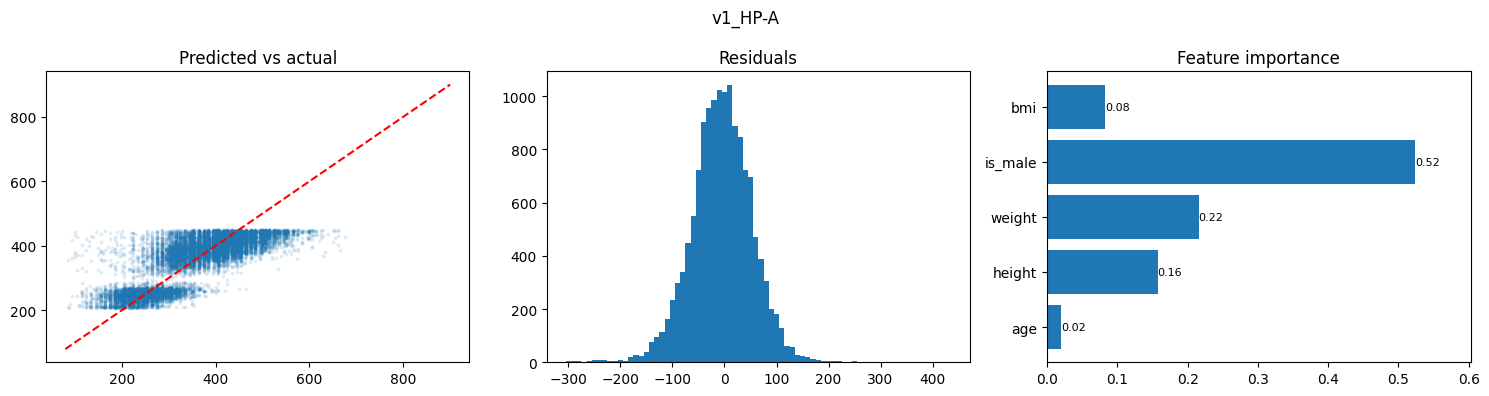

v1_HP-A rmse = 58.96 r2 = 0.622 emissions_kg = 2.3060555928643824e-05


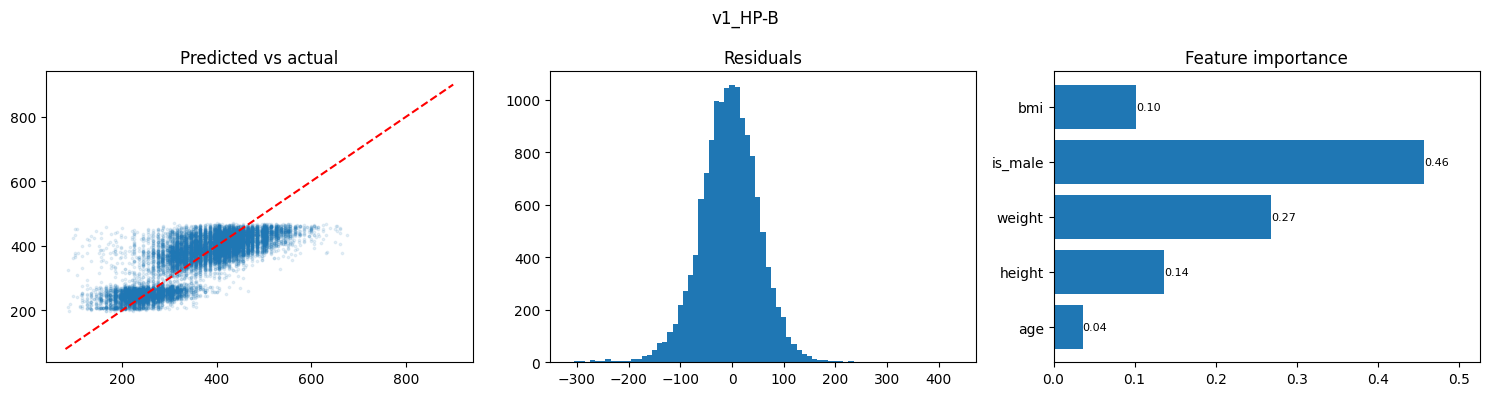

v1_HP-B rmse = 58.56 r2 = 0.627 emissions_kg = 0.0001445210993875074


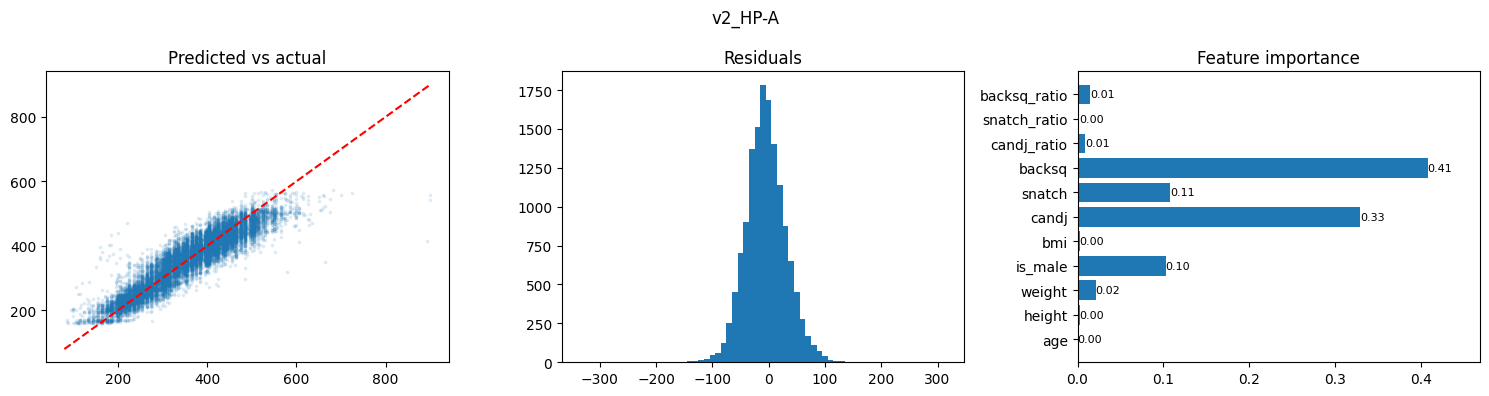

v2_HP-A rmse = 37.32 r2 = 0.849 emissions_kg = 2.379592663599298e-05


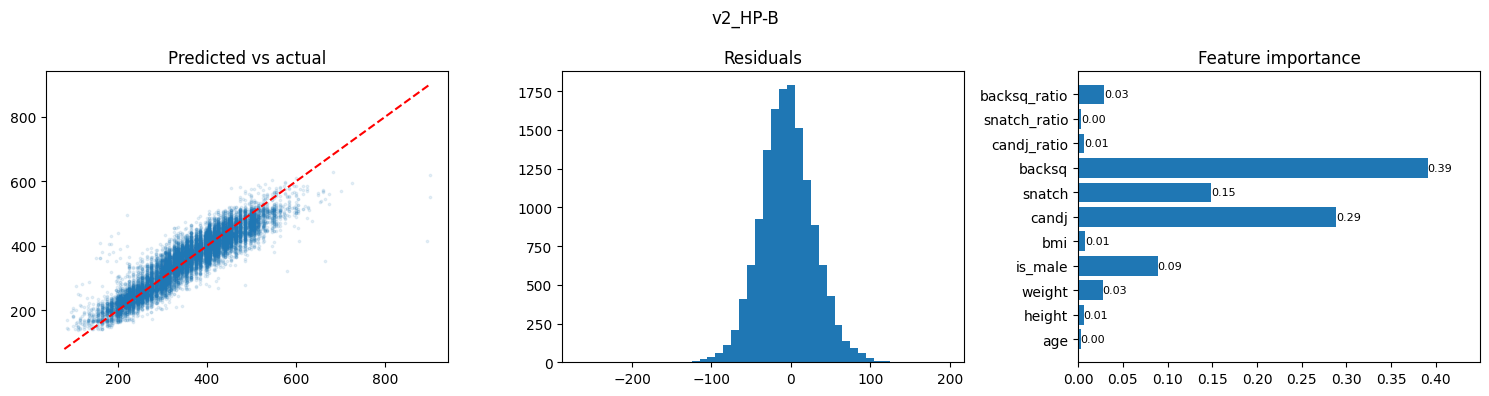

v2_HP-B rmse = 36.75 r2 = 0.853 emissions_kg = 0.00017576381221101741


In [0]:
hyperparams = {
    'HP-A': {'numTrees': 50, 'maxDepth': 6},
    'HP-B': {'numTrees': 100, 'maxDepth': 10},
}
tables = {'v1': (table_v1, v1_cols), 'v2': (table_v2, v2_cols)}

user = spark.sql('select current_user()').first()[0]
experiment = f'/Users/{user}/athletes-deadlift'
mlflow.set_experiment(experiment)

for version, (table, feature_cols) in tables.items():
    # get the features for this version from the feature store
    lookup = FeatureLookup(table_name=table, feature_names=feature_cols, lookup_key='athlete_id')
    training_set = fe.create_training_set(df=labels, feature_lookups=[lookup], label='deadlift')
    data = training_set.load_df()

    # Spark ML wants all the features in one vector column
    data = VectorAssembler(inputCols=feature_cols, outputCol='features').transform(data)
    train, test = data.randomSplit([0.8, 0.2], seed=42)

    for hp_name, params in hyperparams.items():
        run_name = version + '_' + hp_name

        with mlflow.start_run(run_name=run_name):
            # measure the carbon emissions of the training
            tracker = OfflineEmissionsTracker(country_iso_code='USA', save_to_file=False, log_level='error')
            tracker.start()
            rf = RandomForestRegressor(featuresCol='features', labelCol='deadlift', seed=42, **params)
            model = rf.fit(train)
            emissions = tracker.stop()

            predictions = model.transform(test)
            rmse = RegressionEvaluator(labelCol='deadlift', metricName='rmse').evaluate(predictions)
            mae = RegressionEvaluator(labelCol='deadlift', metricName='mae').evaluate(predictions)
            r2 = RegressionEvaluator(labelCol='deadlift', metricName='r2').evaluate(predictions)

            # plot data, summarised in Spark
            # 1) every test athlete for the scatter plot
            points = predictions.select('deadlift', 'prediction').collect()
            # 2) residuals counted in 10 lb bins
            residuals = (predictions.withColumn('bin', F.floor((F.col('deadlift') - F.col('prediction')) / 10) * 10)
                         .groupBy('bin').count().orderBy('bin').collect())

            fig, ax = plt.subplots(1, 3, figsize=(15, 4))
            ax[0].scatter([r['deadlift'] for r in points], [r['prediction'] for r in points], s=3, alpha=0.1)
            ax[0].plot([80, 900], [80, 900], 'r--')
            ax[0].set_title('Predicted vs actual')

            ax[1].bar([r['bin'] for r in residuals], [r['count'] for r in residuals], width=10)
            ax[1].set_title('Residuals')
            bars = ax[2].barh(feature_cols, model.featureImportances.toArray())
            ax[2].bar_label(bars, fmt='%.2f', fontsize=8)
            ax[2].margins(x=0.15)
            ax[2].set_title('Feature importance')
            fig.suptitle(run_name)
            plt.tight_layout()
            plt.show()

            mlflow.log_param('feature_version', version)
            mlflow.log_params(params)
            mlflow.log_metrics({'rmse': rmse, 'mae': mae, 'r2': r2, 'emissions_kg': emissions})

            print(run_name, 'rmse =', round(rmse, 2), 'r2 =', round(r2, 3), 'emissions_kg =', emissions)

## 5. Compare the results (metrics and carbon)

run,rmse,mae,r2,emissions_kg
v1_HP-A,58.961197081729914,45.47673397678291,0.6215164543983862,2.3060555928643824E-5
v1_HP-B,58.5612107666835,45.133448662731944,0.6266342181327736,1.445210993875074E-4
v2_HP-A,37.32275623340907,28.364306251346875,0.8485601003076471,2.379592663599298E-5
v2_HP-B,36.75320368165725,27.956488645669005,0.8531468388699692,1.7576381221101741E-4


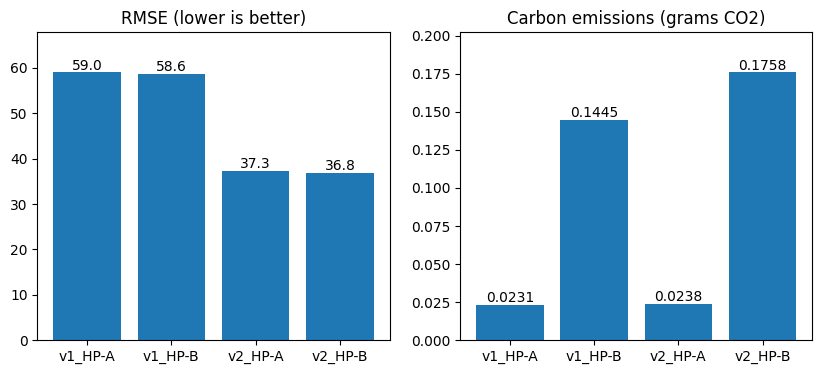

In [0]:
# get the runs from MLflow, keeping the latest run of each name
experiment_id = mlflow.get_experiment_by_name(experiment).experiment_id
latest = {}
for run in sorted(MlflowClient().search_runs([experiment_id]), key=lambda r: r.info.start_time):
    latest[run.info.run_name] = run

rows = [(name, r.data.metrics['rmse'], r.data.metrics['mae'], r.data.metrics['r2'], r.data.metrics['emissions_kg'])
        for name, r in sorted(latest.items())]
results = spark.createDataFrame(rows, ['run', 'rmse', 'mae', 'r2', 'emissions_kg'])
display(results)

names = [r[0] for r in rows]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
bars = ax[0].bar(names, [r[1] for r in rows])
ax[0].bar_label(bars, fmt='%.1f')
ax[0].margins(y=0.15)
ax[0].set_title('RMSE (lower is better)')
bars = ax[1].bar(names, [r[4] * 1000 for r in rows])
ax[1].bar_label(bars, fmt='%.4f')
ax[1].margins(y=0.15)
ax[1].set_title('Carbon emissions (grams CO2)')
plt.show()